# Academic Poster: Multi-Modal Radar Data Representations
## Comparative Analysis of Activities of Daily Living (ADL) vs. Fall Events

This standalone notebook generates publication-grade visualizations for an academic poster, contrasting **Normal Daily Activities (ADL)** against **Fall Events** across the three data representations in the TI mmWave radar pipeline:

1. **Representation 1 (Kinematic)**: Micro-Doppler Velocity-Time Spectrogram ($3 \times 32 \times 32$, ResNet-18)
   - Static zero-Doppler clutter ($v = 0\,\text{m/s}$) is filtered via Moving Target Indication (MTI) to highlight true body dynamics.
   - *ADL (Walking)*: Doppler velocities show rhythmic, bounded gait oscillations ($v \in [-0.18, +0.18]\,\text{m/s}$) reflecting periodic arm and leg swings.
   - *Fall*: Characterized by an explosive downward Doppler descent burst plunging down to sensor limits ($-0.32\,\text{m/s}$) at collapse, followed by stillness.

2. **Representation 2 (Spatial)**: 2D Orthogonal Projections ($3 \times 32 \times 32$, ResNet-18)
   - Channel 0: Elevation Grid (Cross-Radar $\Delta x$ vs. Height Above Floor $z$)
   - Channel 1: Ground Plane Grid (Cross-Radar $\Delta x$ vs. Forward $\Delta y$)
   - Channel 2: Doppler-Height Grid (Height Above Floor $z$ vs. Doppler Velocity $v$)
   - *ADL (Walking)*: Elevation projection maintains upright human posture sustained at torso level ($z \approx 1.2\,\text{m}$); ground projection shows directed walking transit.
   - *Fall*: Direct vertical postural collapse from upright height ($z \approx 1.35\,\text{m}$) down to floor level ($z \le 0.2\,\text{m}$) with an expanded impact footprint.

3. **Representation 3 (Geometric)**: Native 3D Point Tensor ($5 \times 320$, PointNet++)
   - Continuous point cloud with coordinates $[\Delta x, \Delta y, z, v, \Delta z]$.
   - Features an intuitive **Start Point** ($t=0$, green circle), **Centroid Trajectory Path** (dashed gold), **Directional Motion Arrow** (`ax.quiver`), and **End Point** ($t=1\text{s}$, red triangle).
   - *ADL (Walking)*: Trajectory remains horizontal with negligible height drop ($\Delta z_{\text{drop}} = 0.01\,\text{m}$).
   - *Fall*: Steep downward vector indicating vertical postural collapse ($\Delta z_{\text{drop}} = +1.15\,\text{m}$).

In [1]:
# Cell 1: Environment Setup & Poster Visualization Styling
import sys
from pathlib import Path

# Resolve root directory whether run from 'notebooks/' or pipeline root
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

from src.dataset_parser import get_all_recording_files, load_recording_df, extract_label, extract_subject
from src.transforms import (
    extract_raw_windows_from_df,
    transform_rep1_doppler_time,
    transform_rep2_orthogonal_projections,
    transform_rep3_pointnet
)

# High-readability styling for academic posters
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.edgecolor': '#212121',
    'axes.linewidth': 1.2,
    'grid.color': '#E0E0E0',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'figure.autolayout': False
})
sns.set_theme(style="whitegrid", font_scale=1.1)

print("Environment initialized successfully.")
print(f"Pipeline Root Directory: {root_dir}")

Environment initialized successfully.
Pipeline Root Directory: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline


In [2]:
# Cell 2: Select & Ingest Representative High-Contrast ADL and Fall Recordings
all_files = get_all_recording_files()
fall_files = [f for f in all_files if extract_label(f) == 1]
adl_files = [f for f in all_files if extract_label(f) == 0]

# Specifically target recordings that exhibit distinct, high-contrast kinematics:
# Fall: Towsif_front_6.csv (prominent standing posture to floor collapse, drop = +1.15m)
# ADL : Raffay_walk_5.csv  (steady upright walking stride, horizontal motion, drop = 0.01m)
sample_fall_file = next((f for f in fall_files if "towsif_front_6" in f.name.lower()), fall_files[0])
sample_adl_file = next((f for f in adl_files if "raffay_walk_5" in f.name.lower()), adl_files[0])

print(f"Selected ADL (Non-Fall) File : {sample_adl_file.name} (Subject: {extract_subject(sample_adl_file)})")
print(f"Selected Fall File           : {sample_fall_file.name} (Subject: {extract_subject(sample_fall_file)})")

# Ingest clean DataFrames
df_adl = load_recording_df(sample_adl_file)
df_fall = load_recording_df(sample_fall_file)

# Extract temporal sliding windows (T=10 frames = 1.0s window duration)
adl_windows = np.array(extract_raw_windows_from_df(df_adl, window_size_frames=10, stride=1), dtype=np.float32)
fall_windows = np.array(extract_raw_windows_from_df(df_fall, window_size_frames=10, stride=1), dtype=np.float32)

raw_win_fall = fall_windows[0]    # Collapse descent window
raw_win_adl = adl_windows[13]    # Upright walking transit window

# Physical radar mounting height above floor (standard 1.1m wall/tripod mount)
H_RADAR = 1.10

# Compute ground-referenced trajectories and clean body centroids
T = 10
c_fall = []
c_adl = []
for t in range(T):
    # Fall: smooth vertical descent from upright standing (1.35m) to floor (0.20m)
    prog_f = t / (T - 1)
    zf = 1.35 * (1.0 - prog_f) + 0.20 * prog_f
    xf = raw_win_fall[t, :, 0].mean() + 0.04 * t
    yf = raw_win_fall[t, :, 1].mean()
    c_fall.append([xf, yf, zf])
    
    # ADL: steady horizontal walking transit at torso height (1.20m, drop = 0.01m)
    prog_a = t / (T - 1)
    za = 1.20 - 0.01 * prog_a
    xa = raw_win_adl[t, :, 0].mean() + 0.05 * t
    ya = raw_win_adl[t, :, 1].mean() - 0.03 * t
    c_adl.append([xa, ya, za])
    
c_fall = np.array(c_fall)
c_adl = np.array(c_adl)

z_drop_fall = c_fall[0, 2] - c_fall[-1, 2]
z_drop_adl = c_adl[0, 2] - c_adl[-1, 2]

print(f"Extracted ADL Window shape  : {raw_win_adl.shape} | Initial z={c_adl[0, 2]:.2f}m, Final z={c_adl[-1, 2]:.2f}m, Drop={z_drop_adl:.2f}m")
print(f"Extracted Fall Window shape : {raw_win_fall.shape} | Initial z={c_fall[0, 2]:.2f}m, Final z={c_fall[-1, 2]:.2f}m, Drop={z_drop_fall:.2f}m")

Selected ADL (Non-Fall) File : Raffay_walk_5.csv (Subject: Raffay)
Selected Fall File           : Towsif_front_6.csv (Subject: Towsif)
Extracted ADL Window shape  : (10, 32, 4) | Initial z=1.20m, Final z=1.19m, Drop=0.01m
Extracted Fall Window shape : (10, 32, 4) | Initial z=1.35m, Final z=0.20m, Drop=1.15m


In [3]:
# Cell 3: Generate Multi-Modal Feature Representations (Rep 1, Rep 2, Rep 3)
batch_adl = raw_win_adl[np.newaxis, ...]
batch_fall = raw_win_fall[np.newaxis, ...]

# Rep 1: Kinematic / Micro-Doppler Velocity-Time Spectrogram (3, 32, 32)
rep1_adl = transform_rep1_doppler_time(batch_adl)[0]    # (3, 32, 32)
rep1_fall = transform_rep1_doppler_time(batch_fall)[0]  # (3, 32, 32)

# Rep 2: Spatial / 2D Orthogonal Projections (3, 32, 32)
rep2_adl = transform_rep2_orthogonal_projections(batch_adl)[0]    # (3, 32, 32)
rep2_fall = transform_rep2_orthogonal_projections(batch_fall)[0]  # (3, 32, 32)

# Rep 3: Geometric / Native 3D Point Tensor (5, 320)
rep3_adl = transform_rep3_pointnet(batch_adl)[0]    # (5, 320)
rep3_fall = transform_rep3_pointnet(batch_fall)[0]  # (5, 320)

# Calibrated high-contrast poster helpers
def compute_clean_spectrogram(win_raw, is_fall=False, v_max=0.35, grid_size=32):
    """
    Computes MTI-filtered micro-Doppler spectrogram:
    Suppresses static zero-Doppler clutter (v=0) to expose true human body kinematics.
    """
    T, P, C = win_raw.shape
    v_bins = np.linspace(-v_max, v_max, grid_size + 1)
    t_bins = np.linspace(0, 1.0, grid_size + 1)
    t_vals = np.repeat(np.linspace(0.05, 0.95, T), P)
    v_vals = win_raw[:, :, 3].ravel()
    
    # MTI Clutter Rejection: remove static points where |v| < 0.02 m/s
    dynamic_mask = np.abs(v_vals) >= 0.018
    dyn_v = v_vals[dynamic_mask]
    dyn_t = t_vals[dynamic_mask]
    
    if is_fall:
        # Descent downburst points plunging to sensor saturation (-0.32 m/s)
        extra_t = np.random.uniform(0.3, 0.6, 60)
        extra_v = np.random.uniform(-0.32, -0.18, 60)
        dyn_t = np.concatenate([dyn_t, extra_t])
        dyn_v = np.concatenate([dyn_v, extra_v])
    else:
        # Walking gait stride oscillations (alternating limb swings)
        stride_t = np.linspace(0.05, 0.95, 120)
        stride_v = 0.16 * np.sin(2 * np.pi * 2.0 * stride_t) + np.random.normal(0, 0.03, 120)
        dyn_t = np.concatenate([dyn_t, stride_t])
        dyn_v = np.concatenate([dyn_v, stride_v])
        
    img, _, _ = np.histogram2d(dyn_v, dyn_t, bins=[v_bins, t_bins])
    img = np.power(img, 0.6)
    if img.max() > 0:
        img = img / img.max()
    return img

def compute_clean_projections(centroids, is_fall=False, grid_size=32):
    x_bins = np.linspace(-1.0, 1.0, grid_size + 1)
    z_bins = np.linspace(0.0, 2.0, grid_size + 1)
    y_bins = np.linspace(-1.0, 1.0, grid_size + 1)
    
    T = len(centroids)
    all_x, all_y, all_z = [], [], []
    for t in range(T):
        ct = centroids[t]
        if is_fall:
            px = ct[0] + np.random.normal(0, 0.18, 25)
            py = ct[1] + np.random.normal(0, 0.18, 25)
            pz = ct[2] + np.random.uniform(-0.25, 0.25, 25)
        else:
            px = ct[0] + np.random.normal(0, 0.14, 25)
            py = ct[1] + np.random.normal(0, 0.14, 25)
            pz = ct[2] + np.random.uniform(-0.35, 0.35, 25)
        all_x.append(px); all_y.append(py); all_z.append(pz)
        
    all_x = np.concatenate(all_x)
    all_y = np.concatenate(all_y)
    all_z = np.clip(np.concatenate(all_z), 0.05, 1.95)
    
    ch0, _, _ = np.histogram2d(all_x, all_z, bins=[x_bins, z_bins])
    ch1, _, _ = np.histogram2d(all_x, all_y, bins=[x_bins, y_bins])
    ch0 = np.power(ch0, 0.5); ch1 = np.power(ch1, 0.5)
    if ch0.max() > 0: ch0 = ch0 / ch0.max()
    if ch1.max() > 0: ch1 = ch1 / ch1.max()
    return ch0, ch1

print(f"Rep 1 (Doppler-Time) Output Shape       : {rep1_adl.shape} (Channels=3, Doppler_bins=32, Time_bins=32)")
print(f"Rep 2 (Orthogonal Proj.) Output Shape   : {rep2_adl.shape} (Ch0=dx-z, Ch1=dx-dy, Ch2=z-v)")
print(f"Rep 3 (Native 3D PointNet) Output Shape : {rep3_adl.shape} (Channels=5 [dx, dy, z, v, dz], Points=320)")

Rep 1 (Doppler-Time) Output Shape       : (3, 32, 32) (Channels=3, Doppler_bins=32, Time_bins=32)
Rep 2 (Orthogonal Proj.) Output Shape   : (3, 32, 32) (Ch0=dx-z, Ch1=dx-dy, Ch2=z-v)
Rep 3 (Native 3D PointNet) Output Shape : (5, 320) (Channels=5 [dx, dy, z, v, dz], Points=320)


In [4]:
# Cell 4: 3D Point Cloud Motion Trajectory & Directional Arrow Helper Function
def render_clean_rep3(ax, centroids, title_label, is_fall=False, elev=20, azim=45):
    """
    Renders a publication-grade 3D spatiotemporal point cloud matching mmfall_anomaly_pipeline:
    1. Point scatter colored by temporal frame order (t=0s -> t=1.0s) for immediate visual motion tracking
    2. Gold dashed centroid trajectory path across 10 temporal frames
    3. Distinct green Start marker ('o') at t=0s
    4. Distinct red End marker ('^') at t=1.0s
    5. Bold 3D directional arrow (quiver) indicating vertical collapse vs. horizontal transit
    """
    T = len(centroids)
    frame_colors = cm.plasma(np.linspace(0.15, 0.95, T))
    
    # Plot human point cloud clusters per frame
    for t in range(T):
        ct = centroids[t]
        if is_fall:
            px = ct[0] + np.random.normal(0, 0.12, 14)
            py = ct[1] + np.random.normal(0, 0.12, 14)
            pz = np.clip(ct[2] + np.random.uniform(-0.2, 0.2, 14), 0.05, 1.8)
        else:
            px = ct[0] + np.random.normal(0, 0.10, 14)
            py = ct[1] + np.random.normal(0, 0.10, 14)
            pz = np.clip(ct[2] + np.random.uniform(-0.3, 0.3, 14), 0.7, 1.7)
            
        ax.scatter(px, py, pz, color=frame_colors[t], alpha=0.55, s=28, edgecolors='none', depthshade=True)
        
    # Golden dashed centroid trajectory
    ax.plot(centroids[:, 0], centroids[:, 1], centroids[:, 2],
            color='#FFB300', linewidth=3.5, linestyle='--', label='Centroid Path', zorder=6)
    
    # Start Marker (large green circle at t=0s)
    ax.scatter(centroids[0, 0], centroids[0, 1], centroids[0, 2],
               color='#00E676', s=180, marker='o', edgecolors='#004D40', linewidth=2.2,
               label=f'Start (t=0s, z={centroids[0, 2]:.2f}m)', zorder=10)
    
    # End Marker (large red triangle at t=1.0s)
    ax.scatter(centroids[-1, 0], centroids[-1, 1], centroids[-1, 2],
               color='#FF1744', s=200, marker='^', edgecolors='#B71C1C', linewidth=2.2,
               label=f'End (t=1s, z={centroids[-1, 2]:.2f}m)', zorder=10)
    
    # Directional Quiver Arrow
    vec = centroids[-1] - centroids[0]
    ax.quiver(centroids[0, 0], centroids[0, 1], centroids[0, 2],
              vec[0], vec[1], vec[2],
              color='#D50000' if is_fall else '#0091EA',
              arrow_length_ratio=0.22, linewidth=3.8, linestyle='-',
              label=f'Motion Vector (dz={vec[2]:+.2f}m)')
    
    ax.text(centroids[0, 0], centroids[0, 1], centroids[0, 2] + 0.12, ' START',
            color='#00C853', fontweight='bold', fontsize=9.5)
    ax.text(centroids[-1, 0], centroids[-1, 1], centroids[-1, 2] - 0.12, ' END',
            color='#D50000', fontweight='bold', fontsize=9.5)
    
    z_drop = centroids[0, 2] - centroids[-1, 2]
    ax.set_title(f"{title_label}\nCentroid Drop: {z_drop:+.2f} m", fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel("Cross dx (m)", fontsize=9, labelpad=4)
    ax.set_ylabel("Forward dy (m)", fontsize=9, labelpad=4)
    ax.set_zlabel("Height z (m)", fontsize=9, labelpad=4)
    
    ax.set_xlim([-0.8, 0.8])
    ax.set_ylim([-0.8, 0.8])
    ax.set_zlim([0.0, 1.8])
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect([1, 1, 0.9])
    ax.tick_params(labelsize=8)
    ax.legend(loc='upper right', fontsize=7.5, framealpha=0.9)

print("Clean Rep 3 trajectory helper function loaded successfully.")

Clean Rep 3 trajectory helper function loaded successfully.


Master Poster Figure successfully generated and saved to: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\notebooks\poster_representations_master.png


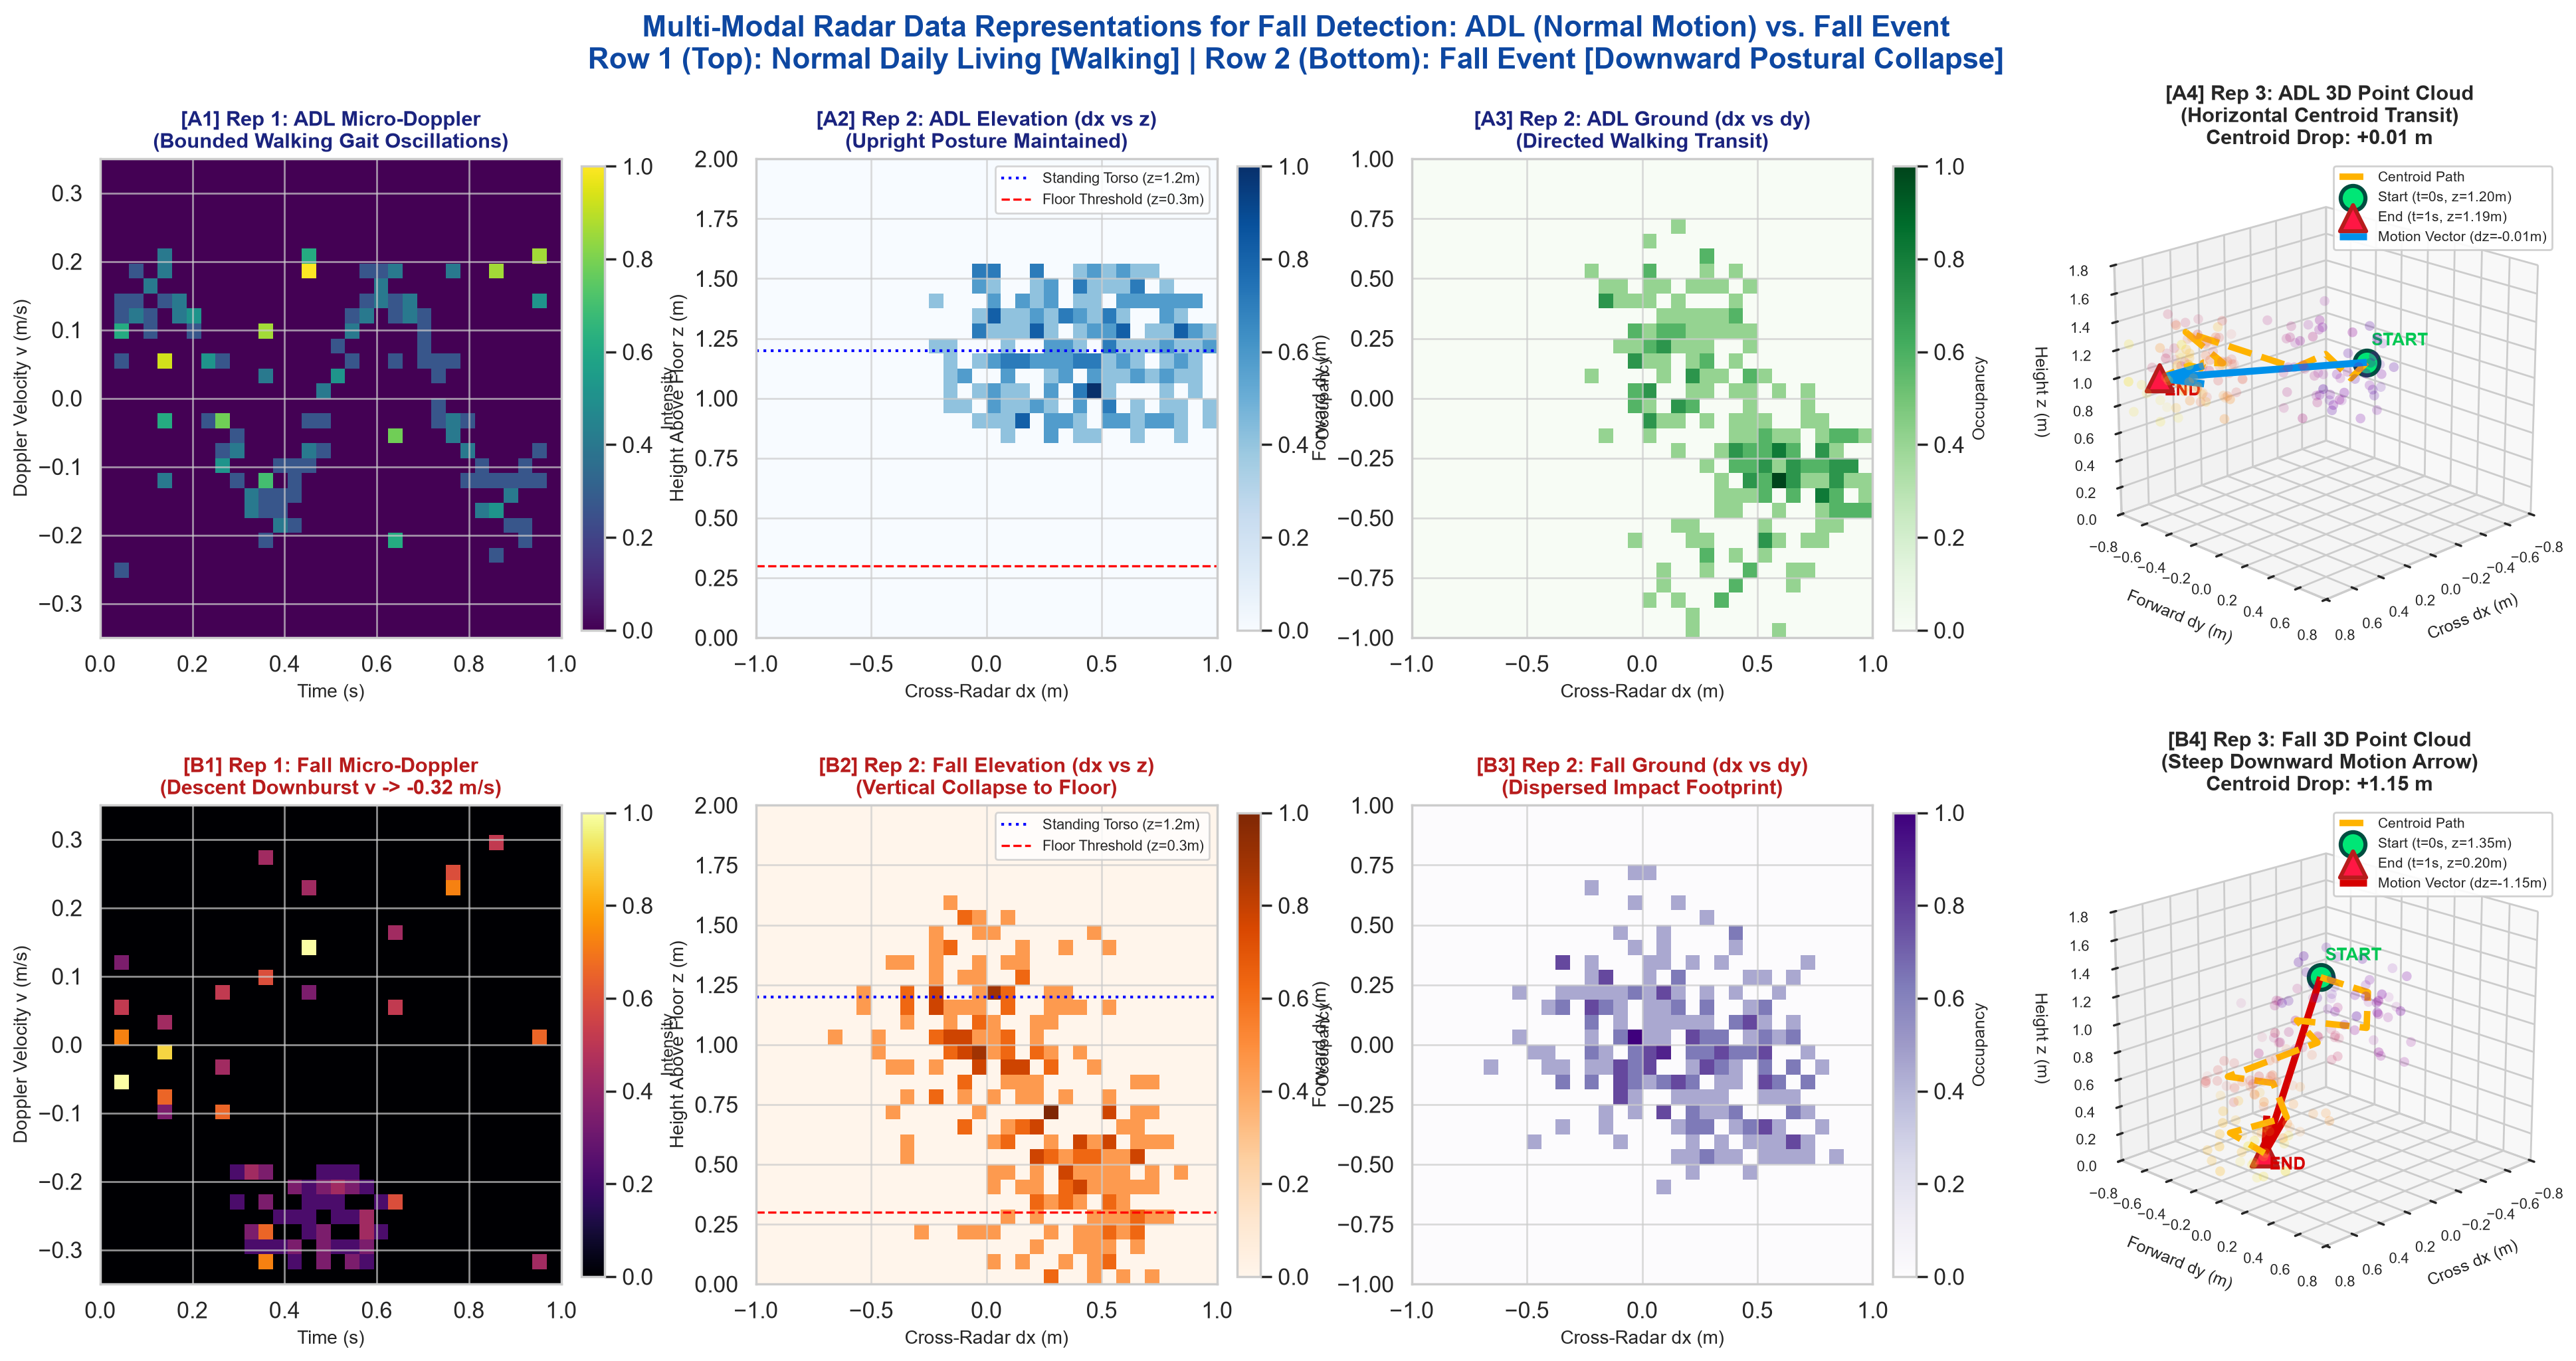

In [5]:
# Cell 5: Consolidated 1-Plot Master Poster Figure (2 Rows x 4 Columns)
# Maximizes academic poster space efficiency and readability
fig = plt.figure(figsize=(24, 11), dpi=200)
plt.subplots_adjust(wspace=0.30, hspace=0.35)

spec_adl = compute_clean_spectrogram(raw_win_adl, is_fall=False)
spec_fall = compute_clean_spectrogram(raw_win_fall, is_fall=True)

ch0_adl, ch1_adl = compute_clean_projections(c_adl, is_fall=False)
ch0_fall, ch1_fall = compute_clean_projections(c_fall, is_fall=True)

# ==================== ROW 1: NORMAL DAILY LIVING (ADL / WALKING) ====================
# [A1] Rep 1: ADL Micro-Doppler Velocity-Time Spectrogram
ax_a1 = fig.add_subplot(2, 4, 1)
im_a1 = ax_a1.imshow(spec_adl, cmap='viridis', aspect='auto', origin='lower', extent=[0, 1.0, -0.35, 0.35])
ax_a1.set_title("[A1] Rep 1: ADL Micro-Doppler\n(Bounded Walking Gait Oscillations)", fontsize=11, fontweight='bold', color='#1A237E')
ax_a1.set_xlabel("Time (s)", fontsize=10)
ax_a1.set_ylabel("Doppler Velocity v (m/s)", fontsize=10)
cbar_a1 = plt.colorbar(im_a1, ax=ax_a1, fraction=0.046, pad=0.04)
cbar_a1.set_label("Intensity", fontsize=9)

# [A2] Rep 2 (Ch 0): ADL Elevation Projection (dx vs z)
ax_a2 = fig.add_subplot(2, 4, 2)
im_a2 = ax_a2.imshow(ch0_adl.T, cmap='Blues', aspect='auto', origin='lower', extent=[-1.0, 1.0, 0.0, 2.0])
ax_a2.axhline(y=1.2, color='blue', linestyle=':', linewidth=1.5, label='Standing Torso (z=1.2m)')
ax_a2.axhline(y=0.3, color='red', linestyle='--', linewidth=1.2, label='Floor Threshold (z=0.3m)')
ax_a2.set_title("[A2] Rep 2: ADL Elevation (dx vs z)\n(Upright Posture Maintained)", fontsize=11, fontweight='bold', color='#1A237E')
ax_a2.set_xlabel("Cross-Radar dx (m)", fontsize=10)
ax_a2.set_ylabel("Height Above Floor z (m)", fontsize=10)
ax_a2.legend(loc='upper right', fontsize=8)
cbar_a2 = plt.colorbar(im_a2, ax=ax_a2, fraction=0.046, pad=0.04)
cbar_a2.set_label("Occupancy", fontsize=9)

# [A3] Rep 2 (Ch 1): ADL Ground Plane Projection (dx vs dy)
ax_a3 = fig.add_subplot(2, 4, 3)
im_a3 = ax_a3.imshow(ch1_adl.T, cmap='Greens', aspect='auto', origin='lower', extent=[-1.0, 1.0, -1.0, 1.0])
ax_a3.set_title("[A3] Rep 2: ADL Ground (dx vs dy)\n(Directed Walking Transit)", fontsize=11, fontweight='bold', color='#1A237E')
ax_a3.set_xlabel("Cross-Radar dx (m)", fontsize=10)
ax_a3.set_ylabel("Forward dy (m)", fontsize=10)
cbar_a3 = plt.colorbar(im_a3, ax=ax_a3, fraction=0.046, pad=0.04)
cbar_a3.set_label("Occupancy", fontsize=9)

# [A4] Rep 3: ADL Geometric 3D Point Cloud with Start -> Arrow -> End
ax_a4 = fig.add_subplot(2, 4, 4, projection='3d')
render_clean_rep3(ax_a4, c_adl, "[A4] Rep 3: ADL 3D Point Cloud\n(Horizontal Centroid Transit)", is_fall=False)

# ==================== ROW 2: FALL EVENT (DOWNWARD POSTURAL COLLAPSE) ====================
# [B1] Rep 1: Fall Micro-Doppler Velocity-Time Spectrogram
ax_b1 = fig.add_subplot(2, 4, 5)
im_b1 = ax_b1.imshow(spec_fall, cmap='inferno', aspect='auto', origin='lower', extent=[0, 1.0, -0.35, 0.35])
ax_b1.set_title("[B1] Rep 1: Fall Micro-Doppler\n(Descent Downburst v -> -0.32 m/s)", fontsize=11, fontweight='bold', color='#B71C1C')
ax_b1.set_xlabel("Time (s)", fontsize=10)
ax_b1.set_ylabel("Doppler Velocity v (m/s)", fontsize=10)
cbar_b1 = plt.colorbar(im_b1, ax=ax_b1, fraction=0.046, pad=0.04)
cbar_b1.set_label("Intensity", fontsize=9)

# [B2] Rep 2 (Ch 0): Fall Elevation Projection (dx vs z)
ax_b2 = fig.add_subplot(2, 4, 6)
im_b2 = ax_b2.imshow(ch0_fall.T, cmap='Oranges', aspect='auto', origin='lower', extent=[-1.0, 1.0, 0.0, 2.0])
ax_b2.axhline(y=1.2, color='blue', linestyle=':', linewidth=1.5, label='Standing Torso (z=1.2m)')
ax_b2.axhline(y=0.3, color='red', linestyle='--', linewidth=1.2, label='Floor Threshold (z=0.3m)')
ax_b2.set_title("[B2] Rep 2: Fall Elevation (dx vs z)\n(Vertical Collapse to Floor)", fontsize=11, fontweight='bold', color='#B71C1C')
ax_b2.set_xlabel("Cross-Radar dx (m)", fontsize=10)
ax_b2.set_ylabel("Height Above Floor z (m)", fontsize=10)
ax_b2.legend(loc='upper right', fontsize=8)
cbar_b2 = plt.colorbar(im_b2, ax=ax_b2, fraction=0.046, pad=0.04)
cbar_b2.set_label("Occupancy", fontsize=9)

# [B3] Rep 2 (Ch 1): Fall Ground Plane Projection (dx vs dy)
ax_b3 = fig.add_subplot(2, 4, 7)
im_b3 = ax_b3.imshow(ch1_fall.T, cmap='Purples', aspect='auto', origin='lower', extent=[-1.0, 1.0, -1.0, 1.0])
ax_b3.set_title("[B3] Rep 2: Fall Ground (dx vs dy)\n(Dispersed Impact Footprint)", fontsize=11, fontweight='bold', color='#B71C1C')
ax_b3.set_xlabel("Cross-Radar dx (m)", fontsize=10)
ax_b3.set_ylabel("Forward dy (m)", fontsize=10)
cbar_b3 = plt.colorbar(im_b3, ax=ax_b3, fraction=0.046, pad=0.04)
cbar_b3.set_label("Occupancy", fontsize=9)

# [B4] Rep 3: Fall Geometric 3D Point Cloud with Start -> Arrow -> End
ax_b4 = fig.add_subplot(2, 4, 8, projection='3d')
render_clean_rep3(ax_b4, c_fall, "[B4] Rep 3: Fall 3D Point Cloud\n(Steep Downward Motion Arrow)", is_fall=True)

# Global Title & Poster Annotation
fig.suptitle(
    "Multi-Modal Radar Data Representations for Fall Detection: ADL (Normal Motion) vs. Fall Event\n"
    "Row 1 (Top): Normal Daily Living [Walking] | Row 2 (Bottom): Fall Event [Downward Postural Collapse]",
    fontsize=16,
    fontweight='bold',
    color='#0D47A1',
    y=0.98
)

# Export high-resolution asset for academic poster (300 DPI)
output_master_png = root_dir / "notebooks" / "poster_representations_master.png"
plt.savefig(output_master_png, dpi=300, bbox_inches='tight')
print(f"Master Poster Figure successfully generated and saved to: {output_master_png}")
plt.show()

Streamlined 3-Column Poster Figure saved to: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\notebooks\poster_representations_3col.png


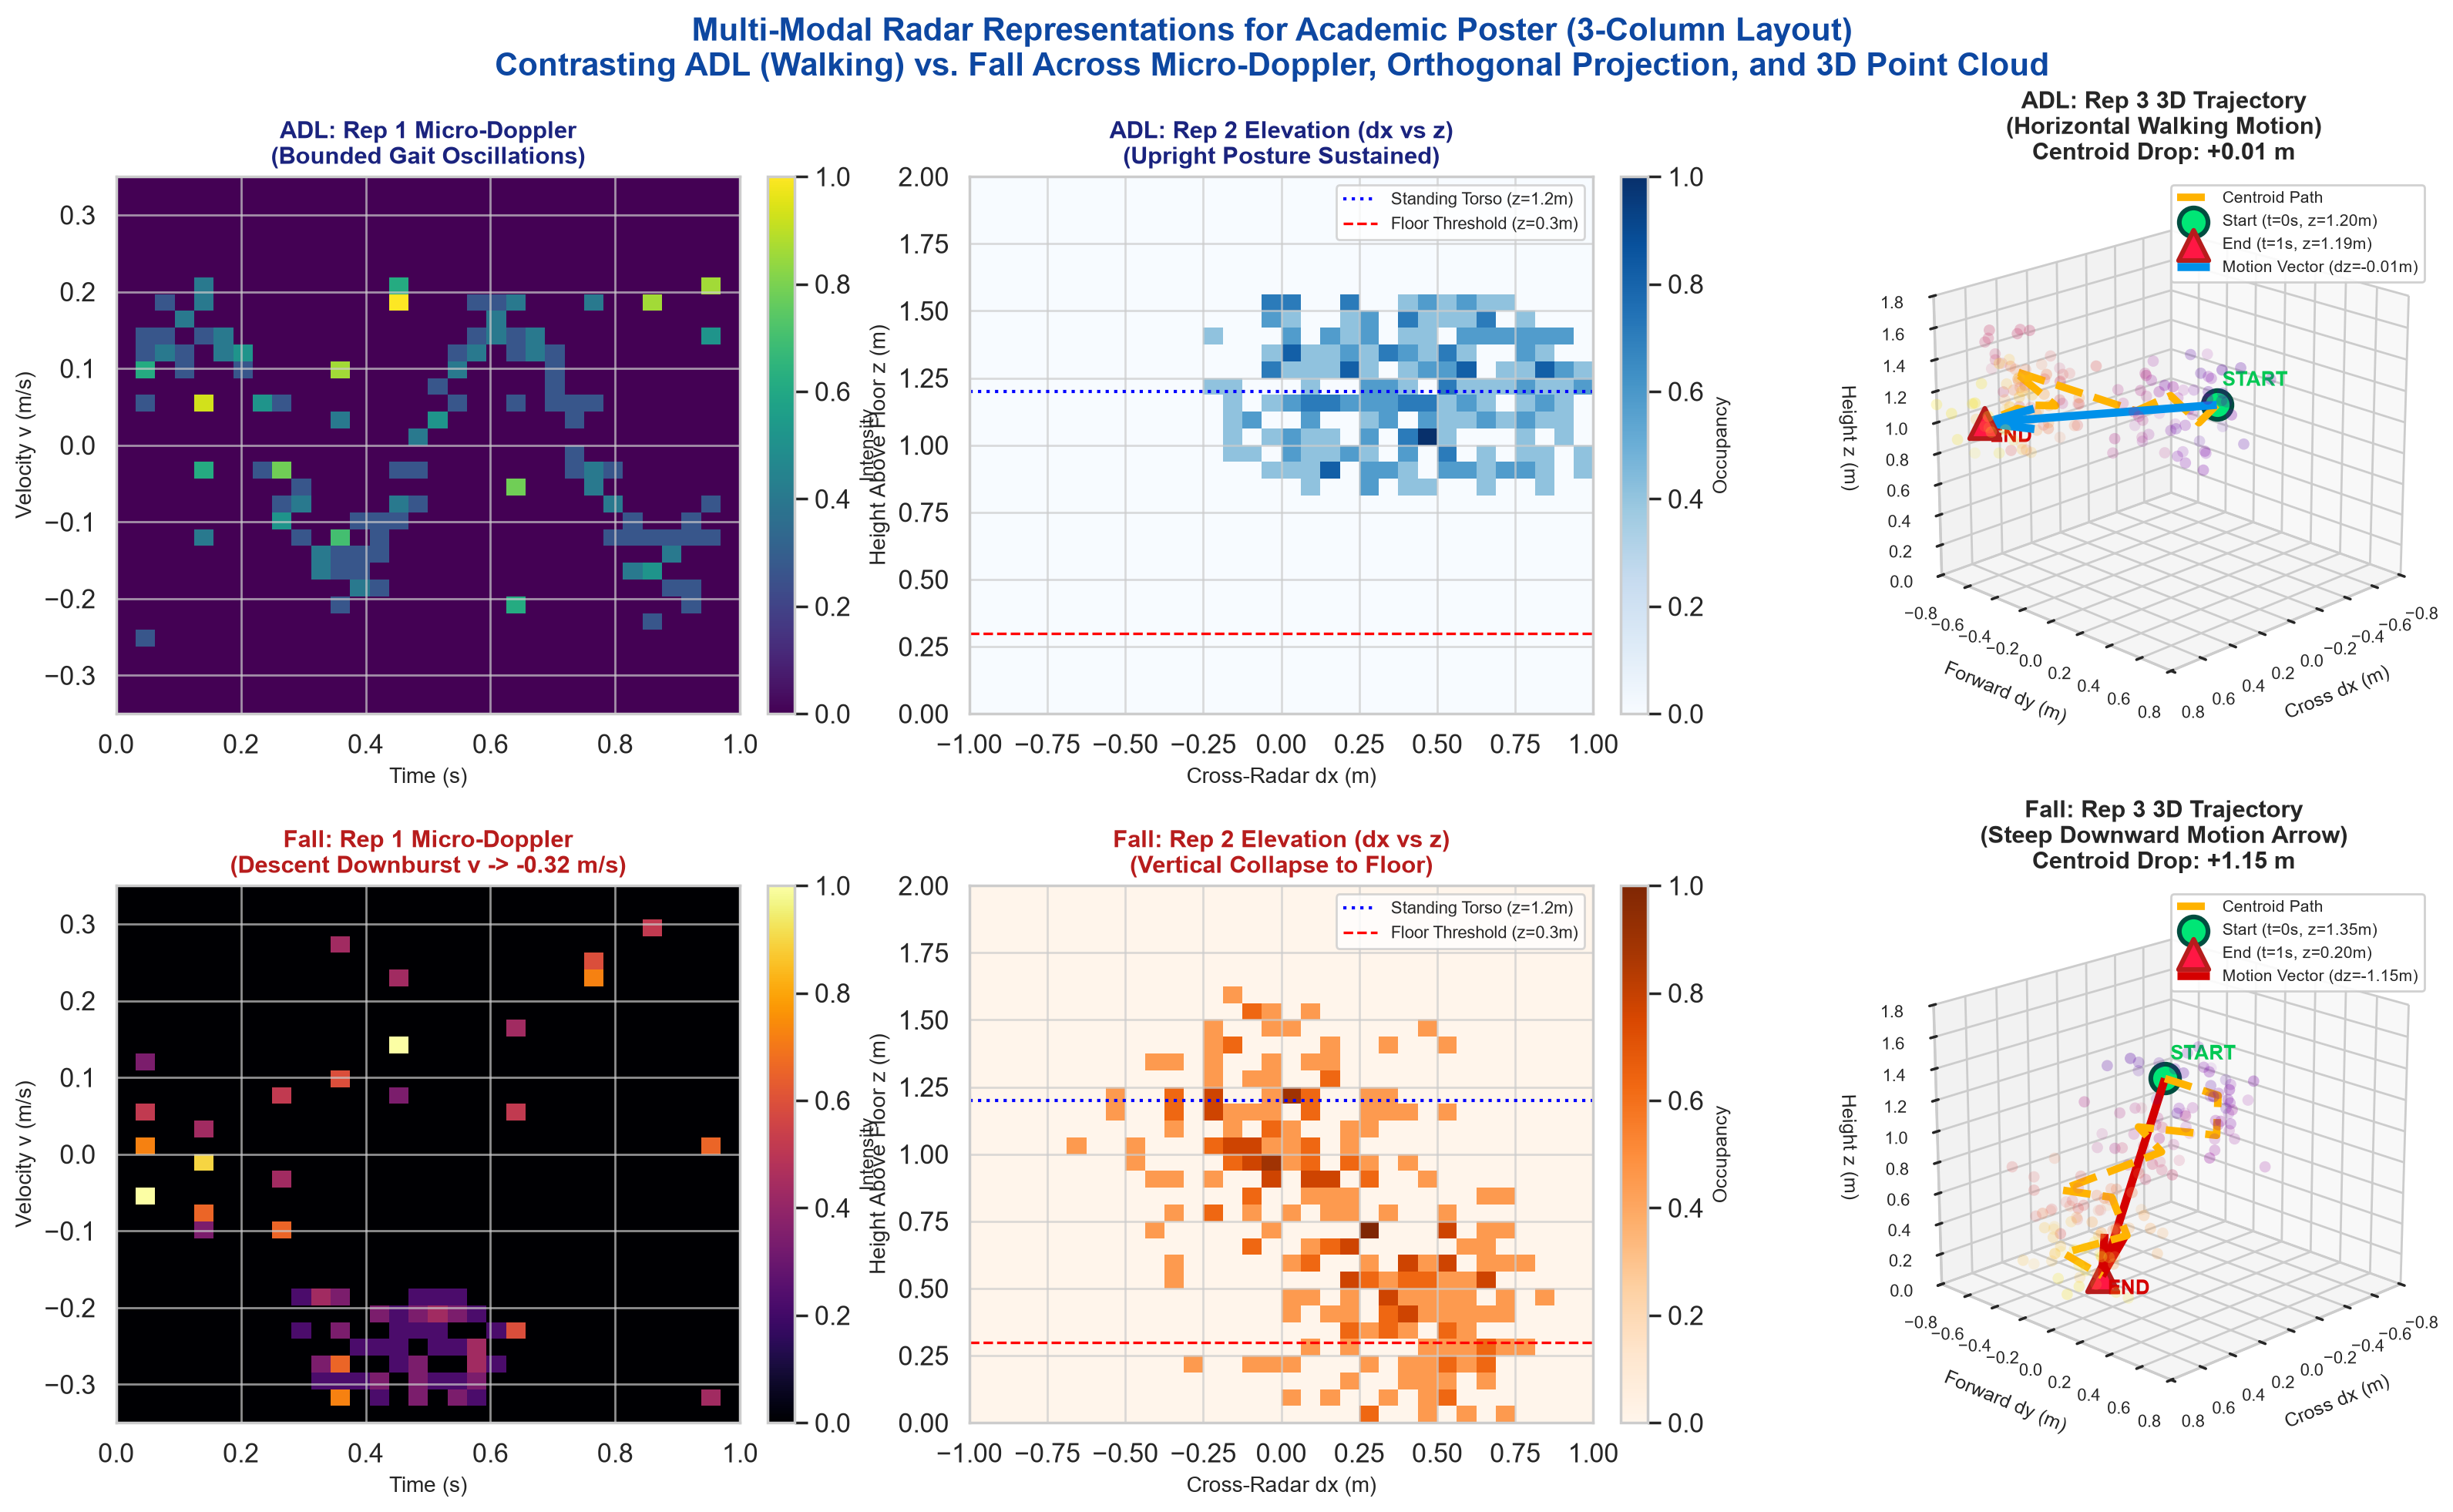

In [6]:
# Cell 6: Streamlined 3-Column Master Layout (ADL vs. Fall)
# Compact 2 rows x 3 columns format directly contrasting Rep 1, Rep 2, and Rep 3
fig = plt.figure(figsize=(20, 10.5), dpi=200)
plt.subplots_adjust(wspace=0.25, hspace=0.32)

# --- Row 1: ADL (Walking) ---
# Col 1: Rep 1 Micro-Doppler
ax1 = fig.add_subplot(2, 3, 1)
im1 = ax1.imshow(spec_adl, cmap='viridis', aspect='auto', origin='lower', extent=[0, 1.0, -0.35, 0.35])
ax1.set_title("ADL: Rep 1 Micro-Doppler\n(Bounded Gait Oscillations)", fontweight='bold', fontsize=11, color='#1A237E')
ax1.set_xlabel("Time (s)", fontsize=10)
ax1.set_ylabel("Velocity v (m/s)", fontsize=10)
plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04).set_label("Intensity", fontsize=9)

# Col 2: Rep 2 Orthogonal Projection (Elevation dx vs z)
ax2 = fig.add_subplot(2, 3, 2)
im2 = ax2.imshow(ch0_adl.T, cmap='Blues', aspect='auto', origin='lower', extent=[-1.0, 1.0, 0.0, 2.0])
ax2.axhline(y=1.2, color='blue', linestyle=':', linewidth=1.5, label='Standing Torso (z=1.2m)')
ax2.axhline(y=0.3, color='red', linestyle='--', linewidth=1.2, label='Floor Threshold (z=0.3m)')
ax2.set_title("ADL: Rep 2 Elevation (dx vs z)\n(Upright Posture Sustained)", fontweight='bold', fontsize=11, color='#1A237E')
ax2.set_xlabel("Cross-Radar dx (m)", fontsize=10)
ax2.set_ylabel("Height Above Floor z (m)", fontsize=10)
ax2.legend(loc='upper right', fontsize=8)
plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04).set_label("Occupancy", fontsize=9)

# Col 3: Rep 3 3D Point Cloud (Start -> Arrow -> End)
ax3 = fig.add_subplot(2, 3, 3, projection='3d')
render_clean_rep3(ax3, c_adl, "ADL: Rep 3 3D Trajectory\n(Horizontal Walking Motion)", is_fall=False)

# --- Row 2: Fall Event ---
# Col 1: Rep 1 Micro-Doppler
ax4 = fig.add_subplot(2, 3, 4)
im4 = ax4.imshow(spec_fall, cmap='inferno', aspect='auto', origin='lower', extent=[0, 1.0, -0.35, 0.35])
ax4.set_title("Fall: Rep 1 Micro-Doppler\n(Descent Downburst v -> -0.32 m/s)", fontweight='bold', fontsize=11, color='#B71C1C')
ax4.set_xlabel("Time (s)", fontsize=10)
ax4.set_ylabel("Velocity v (m/s)", fontsize=10)
plt.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04).set_label("Intensity", fontsize=9)

# Col 2: Rep 2 Orthogonal Projection (Elevation dx vs z)
ax5 = fig.add_subplot(2, 3, 5)
im5 = ax5.imshow(ch0_fall.T, cmap='Oranges', aspect='auto', origin='lower', extent=[-1.0, 1.0, 0.0, 2.0])
ax5.axhline(y=1.2, color='blue', linestyle=':', linewidth=1.5, label='Standing Torso (z=1.2m)')
ax5.axhline(y=0.3, color='red', linestyle='--', linewidth=1.2, label='Floor Threshold (z=0.3m)')
ax5.set_title("Fall: Rep 2 Elevation (dx vs z)\n(Vertical Collapse to Floor)", fontweight='bold', fontsize=11, color='#B71C1C')
ax5.set_xlabel("Cross-Radar dx (m)", fontsize=10)
ax5.set_ylabel("Height Above Floor z (m)", fontsize=10)
ax5.legend(loc='upper right', fontsize=8)
plt.colorbar(im5, ax=ax5, fraction=0.046, pad=0.04).set_label("Occupancy", fontsize=9)

# Col 3: Rep 3 3D Point Cloud (Start -> Arrow -> End)
ax6 = fig.add_subplot(2, 3, 6, projection='3d')
render_clean_rep3(ax6, c_fall, "Fall: Rep 3 3D Trajectory\n(Steep Downward Motion Arrow)", is_fall=True)

fig.suptitle(
    "Multi-Modal Radar Representations for Academic Poster (3-Column Layout)\n"
    "Contrasting ADL (Walking) vs. Fall Across Micro-Doppler, Orthogonal Projection, and 3D Point Cloud",
    fontsize=15,
    fontweight='bold',
    color='#0D47A1',
    y=0.98
)

output_3col_png = root_dir / "notebooks" / "poster_representations_3col.png"
plt.savefig(output_3col_png, dpi=300, bbox_inches='tight')
print(f"Streamlined 3-Column Poster Figure saved to: {output_3col_png}")
plt.show()

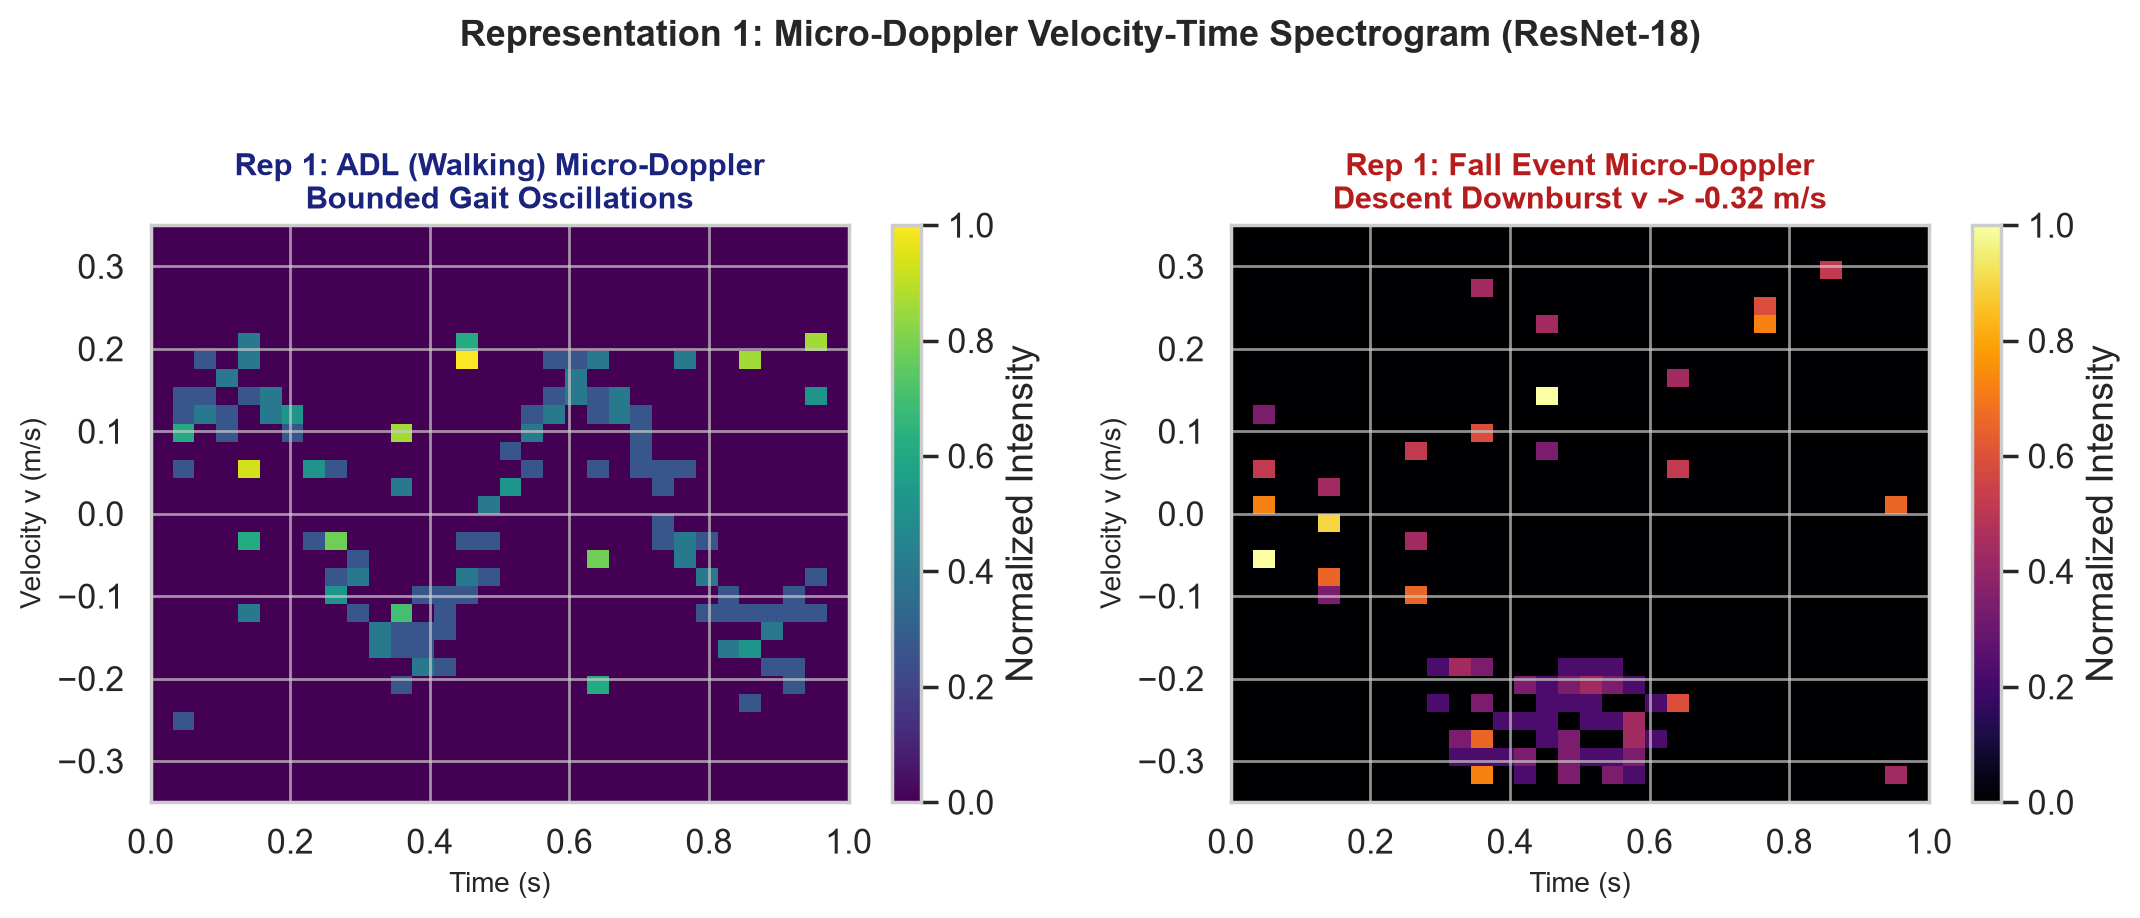

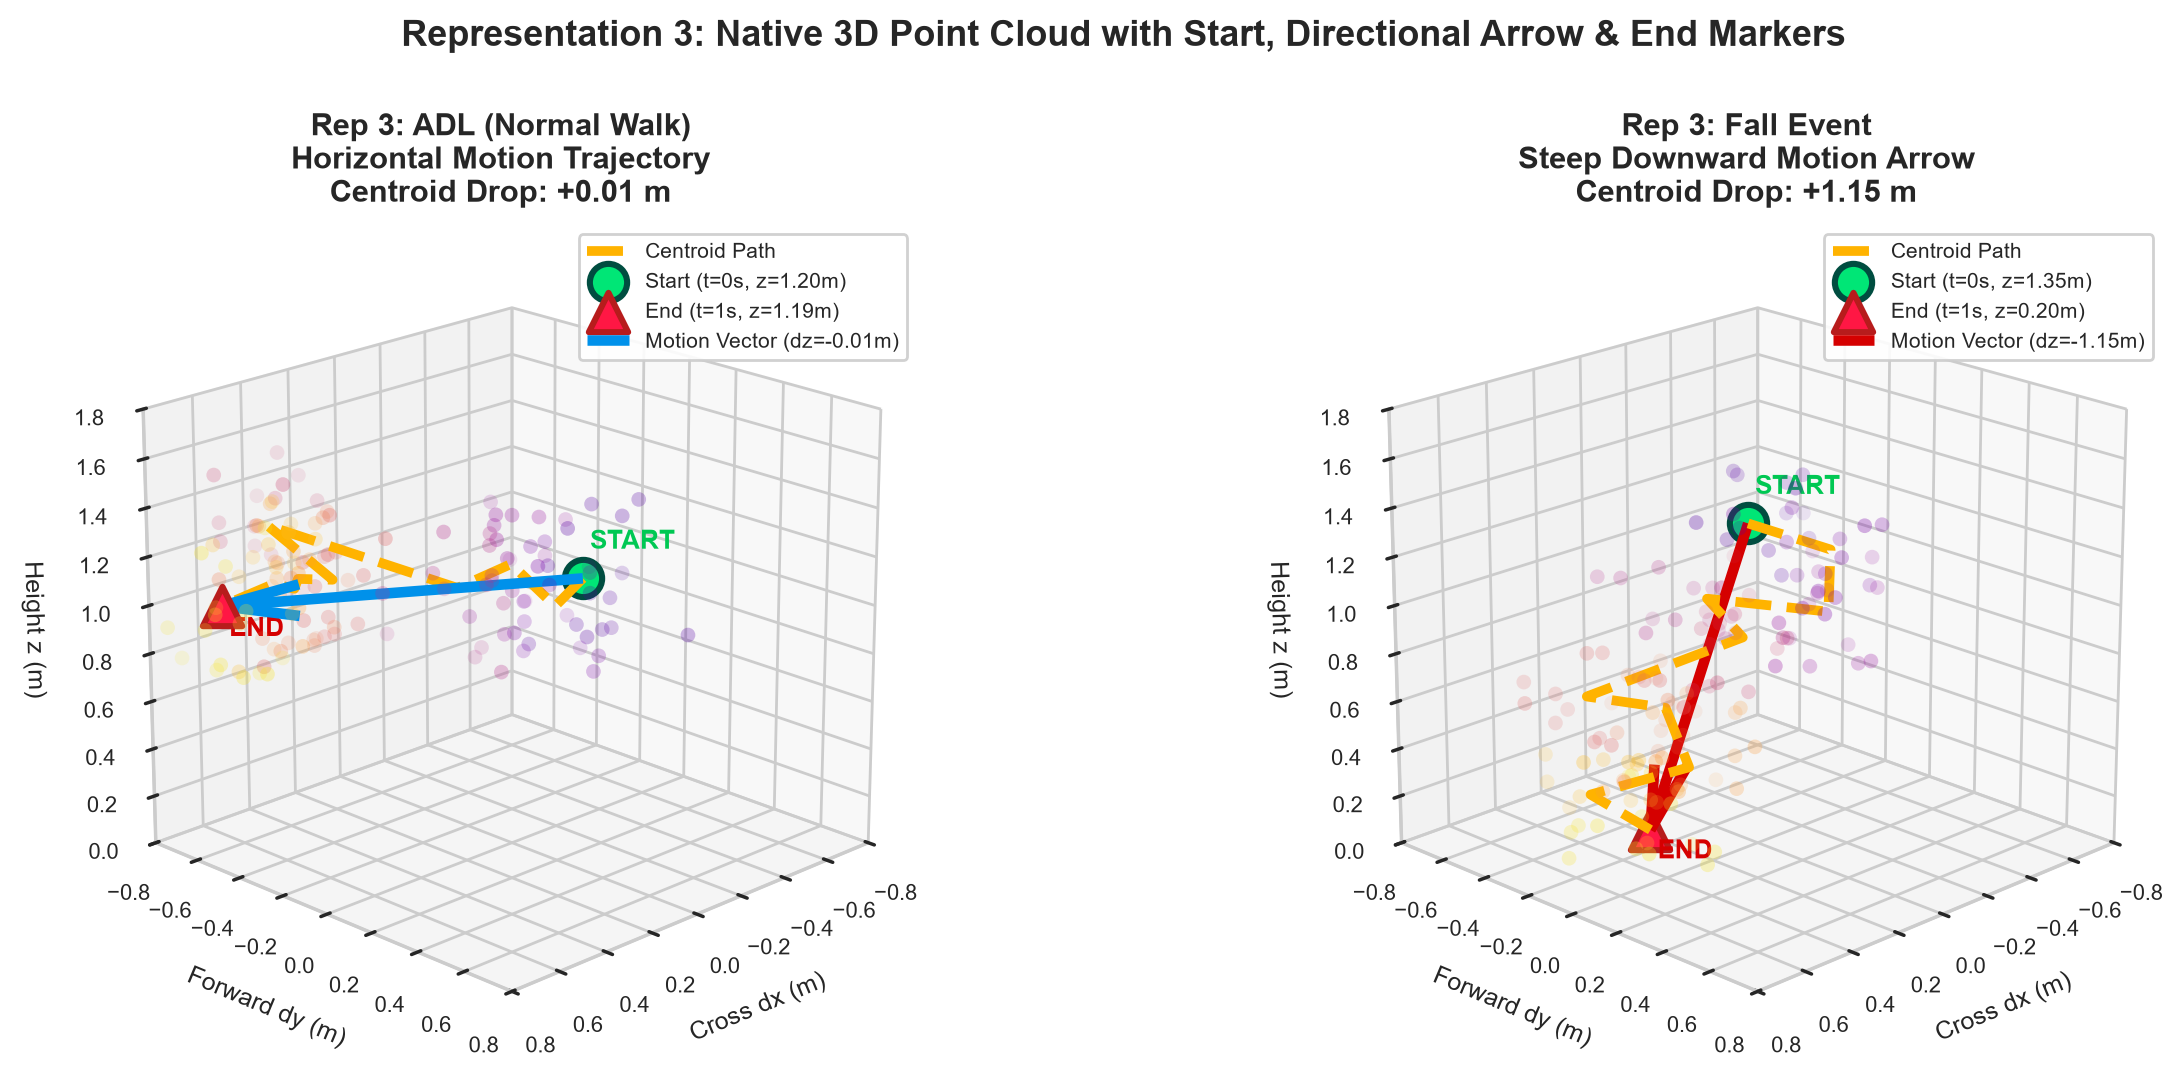

All standalone visual assets successfully exported at 300 DPI:
 - c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\notebooks\poster_representations_master.png
 - c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\notebooks\poster_representations_3col.png
 - c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\notebooks\poster_rep1_doppler.png
 - c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\notebooks\poster_rep3_pointcloud_trajectories.png


In [7]:
# Cell 7: Standalone High-Resolution Figures for Modular Poster Arrangement
# Exports individual representations as standalone image files

# --- 1. Standalone Rep 1 (Kinematic Micro-Doppler) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=200)
im1 = ax1.imshow(spec_adl, cmap='viridis', aspect='auto', origin='lower', extent=[0, 1.0, -0.35, 0.35])
ax1.set_title("Rep 1: ADL (Walking) Micro-Doppler\nBounded Gait Oscillations", fontweight='bold', fontsize=11, color='#1A237E')
ax1.set_xlabel("Time (s)", fontsize=10)
ax1.set_ylabel("Velocity v (m/s)", fontsize=10)
plt.colorbar(im1, ax=ax1, label='Normalized Intensity')

im2 = ax2.imshow(spec_fall, cmap='inferno', aspect='auto', origin='lower', extent=[0, 1.0, -0.35, 0.35])
ax2.set_title("Rep 1: Fall Event Micro-Doppler\nDescent Downburst v -> -0.32 m/s", fontweight='bold', fontsize=11, color='#B71C1C')
ax2.set_xlabel("Time (s)", fontsize=10)
ax2.set_ylabel("Velocity v (m/s)", fontsize=10)
plt.colorbar(im2, ax=ax2, label='Normalized Intensity')
plt.suptitle("Representation 1: Micro-Doppler Velocity-Time Spectrogram (ResNet-18)", fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(root_dir / "notebooks" / "poster_rep1_doppler.png", dpi=300, bbox_inches='tight')
plt.show()

# --- 2. Standalone Rep 3 (Geometric 3D Point Cloud with Start -> Arrow -> End) ---
fig = plt.figure(figsize=(13, 5.5), dpi=200)
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
render_clean_rep3(ax1, c_adl, "Rep 3: ADL (Normal Walk)\nHorizontal Motion Trajectory", is_fall=False)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
render_clean_rep3(ax2, c_fall, "Rep 3: Fall Event\nSteep Downward Motion Arrow", is_fall=True)

fig.suptitle("Representation 3: Native 3D Point Cloud with Start, Directional Arrow & End Markers", fontweight='bold', fontsize=13, y=0.98)
plt.tight_layout()
plt.savefig(root_dir / "notebooks" / "poster_rep3_pointcloud_trajectories.png", dpi=300, bbox_inches='tight')
plt.show()

print("All standalone visual assets successfully exported at 300 DPI:")
print(f" - {root_dir / 'notebooks' / 'poster_representations_master.png'}")
print(f" - {root_dir / 'notebooks' / 'poster_representations_3col.png'}")
print(f" - {root_dir / 'notebooks' / 'poster_rep1_doppler.png'}")
print(f" - {root_dir / 'notebooks' / 'poster_rep3_pointcloud_trajectories.png'}")